# MIL vs mean-pooled logistic regression on the cfDNA tasks

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Both arms are the same 5 outer folds of the same split JSONs on the Cristiano
cohort. The LR arm is a full-batch sweep fit on *mean-pooled* sample
embeddings, so MIL - LR isolates attention pooling over mean pooling with a
linear head held fixed.

The unit of analysis is the task: AUC is averaged over the 5 folds first, then
the 7 (or 14) per-task values enter a paired BCa bootstrap of the mean
difference. Pan-cancer `cancer_vs_healthy` is reported in the printed summary
but is not one of the plotted subsets.

Panel:
- `cfdna_mil_vs_lr_delta`: mean dAUC with paired BCa 95% CI, one bar per task
  subset, per-task deltas overlaid.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: cfdna/data
OUT : cfdna/output


In [2]:
# ── Constants and statistics ──────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sp_stats

COMPARATOR = "LR"
PAN_TASK = "cancer_vs_healthy"
N_BOOTSTRAP = 9999
SEED = 42
BLUE, ORANGE = OKABE_ITO["blue"], OKABE_ITO["orange"]
PANEL_RC = {"xtick.labelsize": 7, "ytick.labelsize": 7, "lines.linewidth": 1}


def paired_bca(a, b, n_resamples=N_BOOTSTRAP, seed=SEED):
    """BCa 95% CI of mean(a - b) over tasks."""
    d = np.asarray(a, float) - np.asarray(b, float)
    if len(d) < 2:
        v = float(d[0])
        return v, v, v
    res = sp_stats.bootstrap(
        (d,), np.mean, n_resamples=n_resamples, confidence_level=0.95,
        method="BCa", random_state=np.random.default_rng(seed))
    return (float(np.mean(d)), float(res.confidence_interval.low),
            float(res.confidence_interval.high))


def mean_bca(vals, n_resamples=N_BOOTSTRAP, seed=SEED):
    a = np.asarray(vals, float)
    if len(a) < 2:
        v = float(a[0])
        return v, v, v
    res = sp_stats.bootstrap(
        (a,), np.mean, n_resamples=n_resamples, confidence_level=0.95,
        method="BCa", random_state=np.random.default_rng(seed))
    return (float(np.mean(a)), float(res.confidence_interval.low),
            float(res.confidence_interval.high))


def wins_losses(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return int(np.sum(a - b > 0)), int(np.sum(b - a > 0))


df = pd.read_csv(DATA / "cfdna_mil_vs_lr_per_task_auc.csv")
df_14 = df[df["task"] != PAN_TASK]
SUBSETS = [
    ("vs Healthy\n(n=7)", df_14[df_14["comparison"] == "vs_healthy"]),
    ("vs Other Cancers\n(n=7)", df_14[df_14["comparison"] == "vs_other_cancers"]),
    ("Combined\n(n=14)", df_14),
]
print(df.to_string(index=False))

                              task     cancer       comparison  n_folds_mil  n_folds_cmp      MIL      LR  MIL_minus_LR
       Bile_duct_cancer_vs_healthy  Bile_duct       vs_healthy            5            5 0.946154 0.94770     -0.001546
          Breast_cancer_vs_healthy     Breast       vs_healthy            5            5 0.861913 0.82250      0.039413
      Colorectal_cancer_vs_healthy Colorectal       vs_healthy            5            5 0.957821 0.90780      0.050021
         Gastric_cancer_vs_healthy    Gastric       vs_healthy            5            5 0.955641 0.93434      0.021301
            Lung_cancer_vs_healthy       Lung       vs_healthy            5            5 0.851458 0.81400      0.037458
         Ovarian_cancer_vs_healthy    Ovarian       vs_healthy            5            5 0.927272 0.80420      0.123072
      Pancreatic_cancer_vs_healthy Pancreatic       vs_healthy            5            5 0.807692 0.84064     -0.032948
 Bile_duct_cancer_vs_other_cancers  Bile

saved: cfdna/output/cfdna_mil_vs_lr_delta.pdf
saved: cfdna/output/cfdna_mil_vs_lr_delta.png
saved: cfdna/output/cfdna_mil_vs_lr_delta.svg
saved: cfdna/output/cfdna_mil_vs_lr_delta.tsv


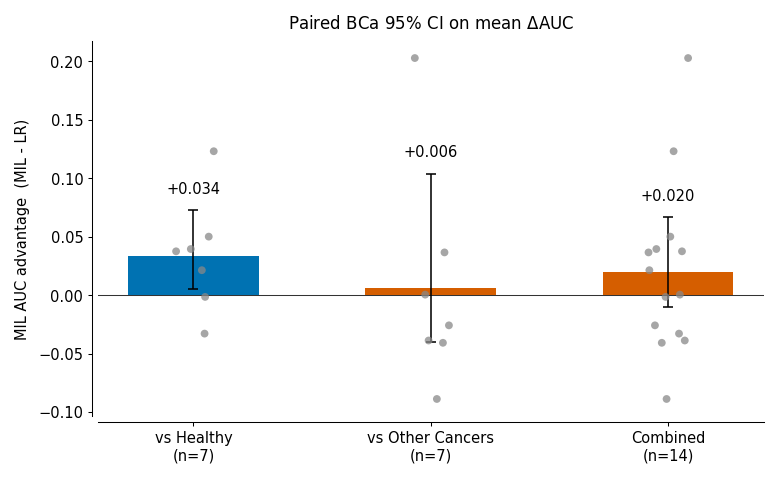

In [3]:
# ── Figure: paired BCa 95% CI on mean dAUC ────────────────────────────────────
# Bar is blue where the CI excludes zero, orange where it does not, matching the
# MIL-vs-SVM panel this figure is the counterpart to.
with plt.rc_context(PANEL_RC):
    fig, ax = plt.subplots(figsize=(5.2, 3.2))
    x = np.arange(len(SUBSETS))

    deltas, lo_err, hi_err, hi_raw, cols = [], [], [], [], []
    for _, sub in SUBSETS:
        d, lo, hi = paired_bca(sub["MIL"].values, sub[COMPARATOR].values)
        deltas.append(d)
        lo_err.append(d - lo)
        hi_err.append(hi - d)
        hi_raw.append(hi)
        cols.append(BLUE if lo > 0 else ORANGE)

    ax.bar(x, deltas, width=0.55, color=cols, linewidth=0, zorder=2,
           yerr=[lo_err, hi_err], capsize=2.5,
           error_kw={"linewidth": 0.75, "capthick": 0.75, "color": "#333333"})

    rng = np.random.default_rng(SEED)
    for j, (_, sub) in enumerate(SUBSETS):
        pts = sub["MIL"].values - sub[COMPARATOR].values
        jitter = rng.uniform(-0.09, 0.09, size=len(pts))
        ax.scatter(np.full(len(pts), j) + jitter, pts, color="#888888",
                   alpha=0.75, s=14, zorder=3, edgecolor="none")

    for j, d, hi in zip(range(len(SUBSETS)), deltas, hi_raw):
        ax.text(j, hi + 0.012, f"{d:+.3f}", ha="center", va="bottom", fontsize=7)

    ax.axhline(0, color="#333333", linewidth=0.5, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels([s[0] for s in SUBSETS], fontsize=7)
    ax.set_ylabel(f"MIL AUC advantage  (MIL - {COMPARATOR})")
    ax.set_title("Paired BCa 95% CI on mean $\\Delta$AUC", fontsize=8)
    ax.spines["left"].set_position(("outward", 3))
    ax.spines["bottom"].set_position(("outward", 3))
    ax.tick_params(axis="both", which="both", length=2, pad=2)
    fig.tight_layout()

    source = pd.DataFrame({
        "subset": [lab.replace("\n", " ") for lab, _ in SUBSETS],
        "n_tasks": [len(s) for _, s in SUBSETS],
        "delta_mean": deltas,
        "delta_lo": [d - e for d, e in zip(deltas, lo_err)],
        "delta_hi": hi_raw,
    })
    savefig(fig, OUT, "cfdna_mil_vs_lr_delta", data=source)
    plt.show()

In [4]:
# ── Printed summary, including the pan-cancer task ────────────────────────────
summary = []
for label, sub in SUBSETS + [("pan-cancer\n(n=1)", df[df["task"] == PAN_TASK])]:
    mil_m, mil_lo, mil_hi = mean_bca(sub["MIL"].values)
    cmp_m, cmp_lo, cmp_hi = mean_bca(sub[COMPARATOR].values)
    d, d_lo, d_hi = paired_bca(sub["MIL"].values, sub[COMPARATOR].values)
    w, l = wins_losses(sub["MIL"].values, sub[COMPARATOR].values)
    summary.append({"subset": label.replace("\n", " "), "n_tasks": len(sub),
                    "MIL_mean": mil_m, "MIL_lo": mil_lo, "MIL_hi": mil_hi,
                    f"{COMPARATOR}_mean": cmp_m, f"{COMPARATOR}_lo": cmp_lo,
                    f"{COMPARATOR}_hi": cmp_hi, "delta_mean": d,
                    "delta_lo": d_lo, "delta_hi": d_hi, "wins": w, "losses": l})
df_summary = pd.DataFrame(summary)

print(f"=== MIL vs {COMPARATOR} (mean-pooled) - paired BCa 95% CI on mean dAUC ===")
for _, r in df_summary.iterrows():
    sig = "*" if r["delta_lo"] > 0 else " "
    print(f"{sig} {r['subset']:22s} n={int(r['n_tasks']):>2d}  "
          f"MIL={r['MIL_mean']:.4f}  {COMPARATOR}={r[f'{COMPARATOR}_mean']:.4f}  "
          f"dAUC={r['delta_mean']:+.4f} [{r['delta_lo']:+.4f}, {r['delta_hi']:+.4f}]  "
          f"W/L={int(r['wins'])}/{int(r['losses'])}")

=== MIL vs LR (mean-pooled) - paired BCa 95% CI on mean dAUC ===
* vs Healthy (n=7)       n= 7  MIL=0.9011  LR=0.8673  dAUC=+0.0338 [+0.0055, +0.0725]  W/L=5/2
  vs Other Cancers (n=7) n= 7  MIL=0.7475  LR=0.7411  dAUC=+0.0065 [-0.0401, +0.1040]  W/L=3/4
  Combined (n=14)        n=14  MIL=0.8243  LR=0.8042  dAUC=+0.0201 [-0.0105, +0.0667]  W/L=8/6
* pan-cancer (n=1)       n= 1  MIL=0.8536  LR=0.8241  dAUC=+0.0295 [+0.0295, +0.0295]  W/L=1/0
